# Machine Failure Prediction

Predicting whether a factory machine is running normally or abnormally from its sensor readings. Only about 3.4% of readings are abnormal, so models are compared on F1 score for the abnormal class rather than accuracy.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV

warnings.filterwarnings("ignore")

## Loading the data

In [2]:
df = pd.read_csv("data/factory_data.csv")

## 1. Exploratory Data Analysis

Steps:
1. Understand the data
2. Clean the data and handle missing values
3. Visualise the data

### 1.1 Understand the data

In [3]:
print("Shape:", df.shape)
df.info()
df.head()

Shape: (20000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unique ID             20000 non-null  int64  
 1   Product ID            20000 non-null  object 
 2   Quality               19009 non-null  object 
 3   Ambient T (C)         20000 non-null  float64
 4   Process T (C)         19600 non-null  float64
 5   Rotation Speed (rpm)  18812 non-null  float64
 6   Torque (Nm)           20000 non-null  float64
 7   Tool Wear (min)       20000 non-null  int64  
 8   Machine Status        20000 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 1.4+ MB


,Unique ID,Product ID,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
0,1,K12965,M,24.95,35.45,1551.0,42.8,0,0
1,2,Z62710,L,25.05,35.55,1408.0,46.3,3,0
2,3,T20224,L,24.95,35.35,1498.0,49.4,5,0
3,4,Z33024,L,25.05,35.45,1433.0,39.5,7,0
4,5,Z52839,L,25.05,35.55,1408.0,40.0,9,0


In [4]:
# Check for missing values
df.isna().sum()

Unique ID                  0
Product ID                 0
Quality                  991
Ambient T (C)              0
Process T (C)            400
Rotation Speed (rpm)    1188
Torque (Nm)                0
Tool Wear (min)            0
Machine Status             0
dtype: int64

In [5]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

### 1.2 Clean the data and handle missing values

In [6]:
# Drop duplicate rows
df = df.drop_duplicates()

In [7]:
# Drop rows with missing values
df.dropna(inplace=True)

In [8]:
# Check the data after cleaning
print("After cleaning:")
print("Shape:", df.shape)
df.isna().sum().sort_values()

After cleaning:
Shape: (17529, 9)


Unique ID               0
Product ID              0
Quality                 0
Ambient T (C)           0
Process T (C)           0
Rotation Speed (rpm)    0
Torque (Nm)             0
Tool Wear (min)         0
Machine Status          0
dtype: int64

In [9]:
# The ID columns only identify a reading, so they aren't useful features
df = df.drop(columns=["Unique ID", "Product ID"])
df.head()

,Quality,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status
0,M,24.95,35.45,1551.0,42.8,0,0
1,L,25.05,35.55,1408.0,46.3,3,0
2,L,24.95,35.35,1498.0,49.4,5,0
3,L,25.05,35.45,1433.0,39.5,7,0
4,L,25.05,35.55,1408.0,40.0,9,0


In [10]:
# One-hot encode product quality (L / M / H), then store the True/False columns as 0/1
df = pd.get_dummies(df, columns=["Quality"], drop_first=True)
df['Quality_M'] = df['Quality_M'].astype(int)
df['Quality_L'] = df['Quality_L'].astype(int)
df.head()

,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status,Quality_L,Quality_M
0,24.95,35.45,1551.0,42.8,0,0,0,1
1,25.05,35.55,1408.0,46.3,3,0,1,0
2,24.95,35.35,1498.0,49.4,5,0,1,0
3,25.05,35.45,1433.0,39.5,7,0,1,0
4,25.05,35.55,1408.0,40.0,9,0,1,0


In [11]:
df.describe()


,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Machine Status,Quality_L,Quality_M
count,17529.000000,17529.000000,17529.000000,17529.000000,17529.000000,17529.000000,17529.000000,17529.000000
mean,26.904475,36.903112,1538.831765,39.992316,108.148782,0.033830,0.597695,0.301044
std,2.003527,1.487427,178.981671,9.971289,63.646264,0.180796,0.490377,0.458725
min,22.150000,32.550000,1168.000000,4.200000,0.000000,0.000000,0.000000,0.000000
25%,25.250000,35.750000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000
50%,26.950000,36.950000,1503.000000,40.100000,108.000000,0.000000,1.000000,0.000000
75%,28.450000,37.950000,1613.000000,46.800000,163.000000,0.000000,1.000000,1.000000
max,31.350000,40.750000,2874.000000,76.600000,253.000000,1.000000,1.000000,1.000000


### 1.3 Visualise the data

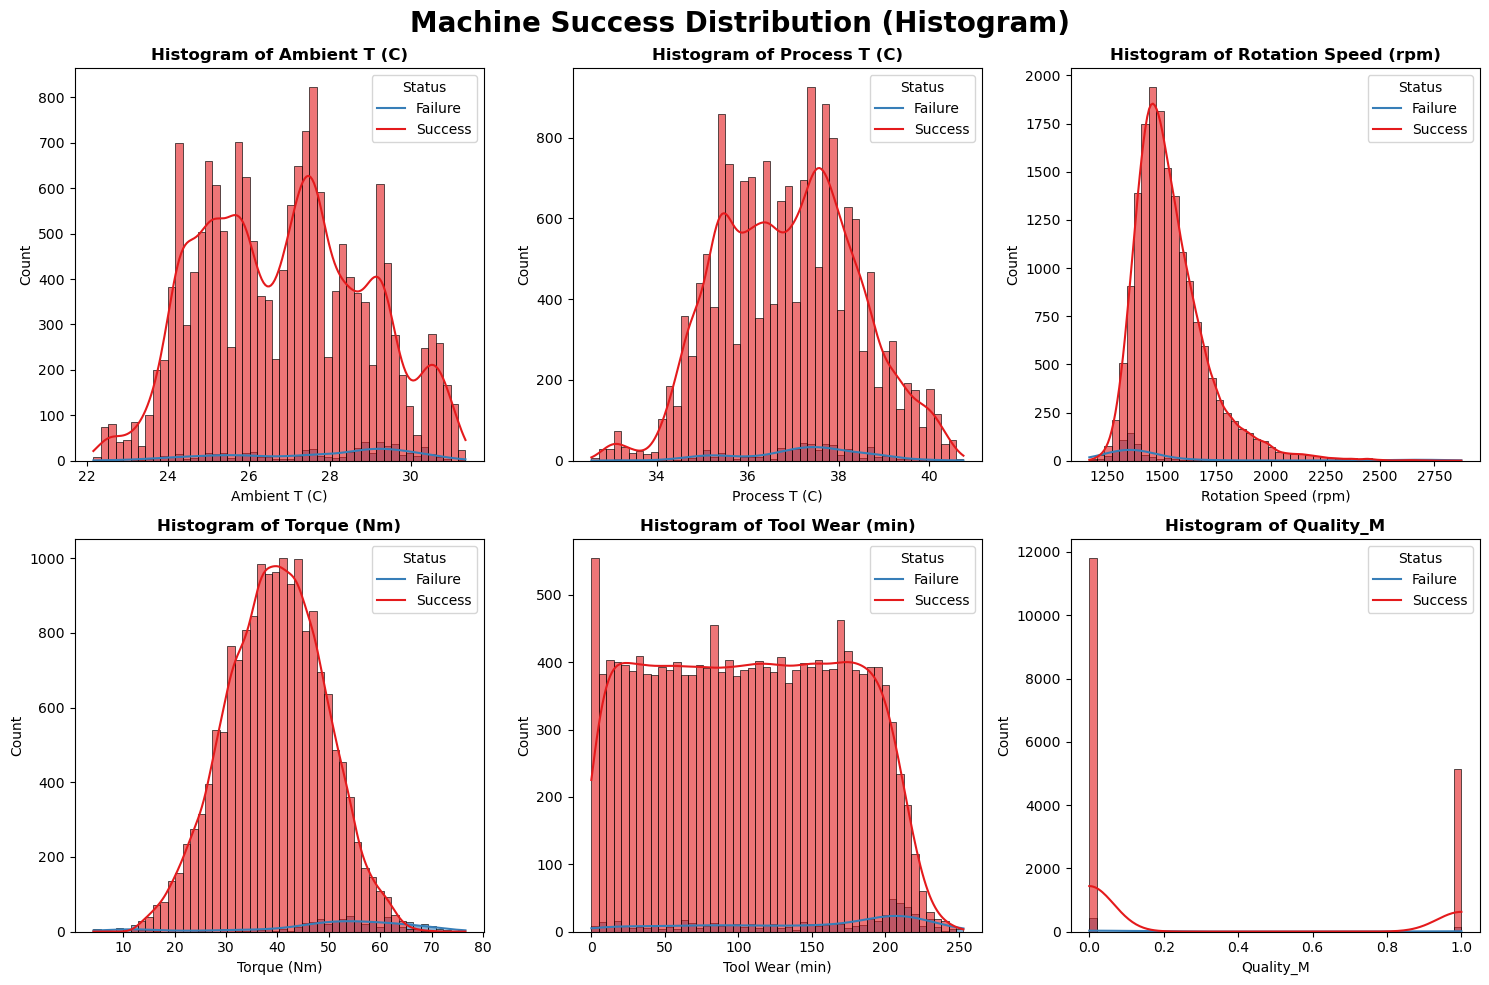

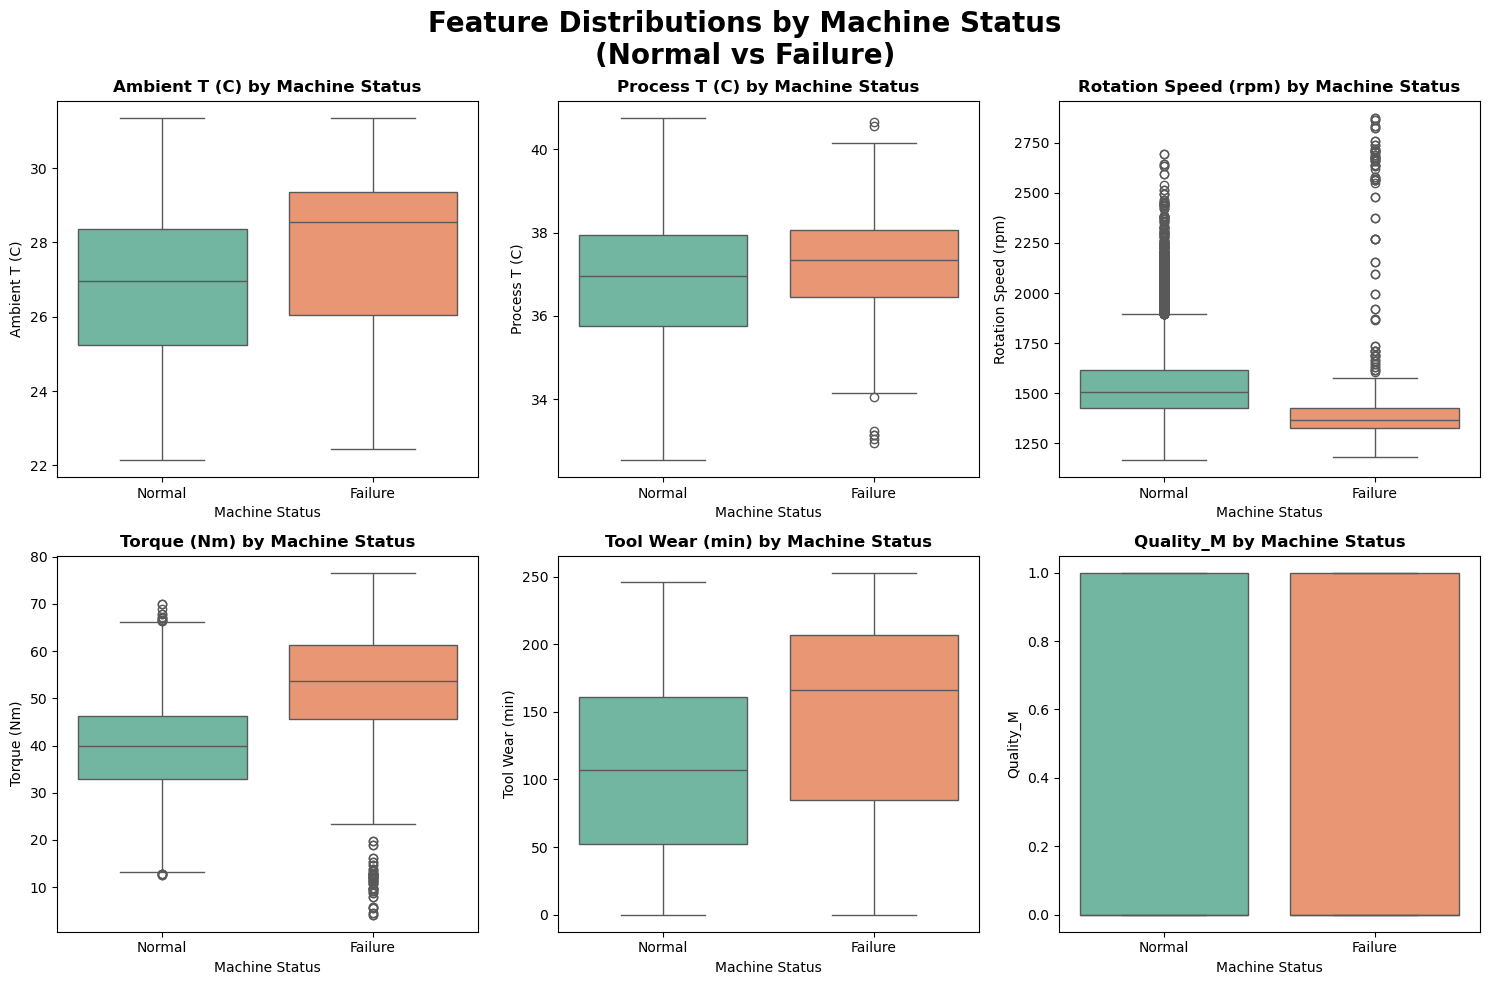

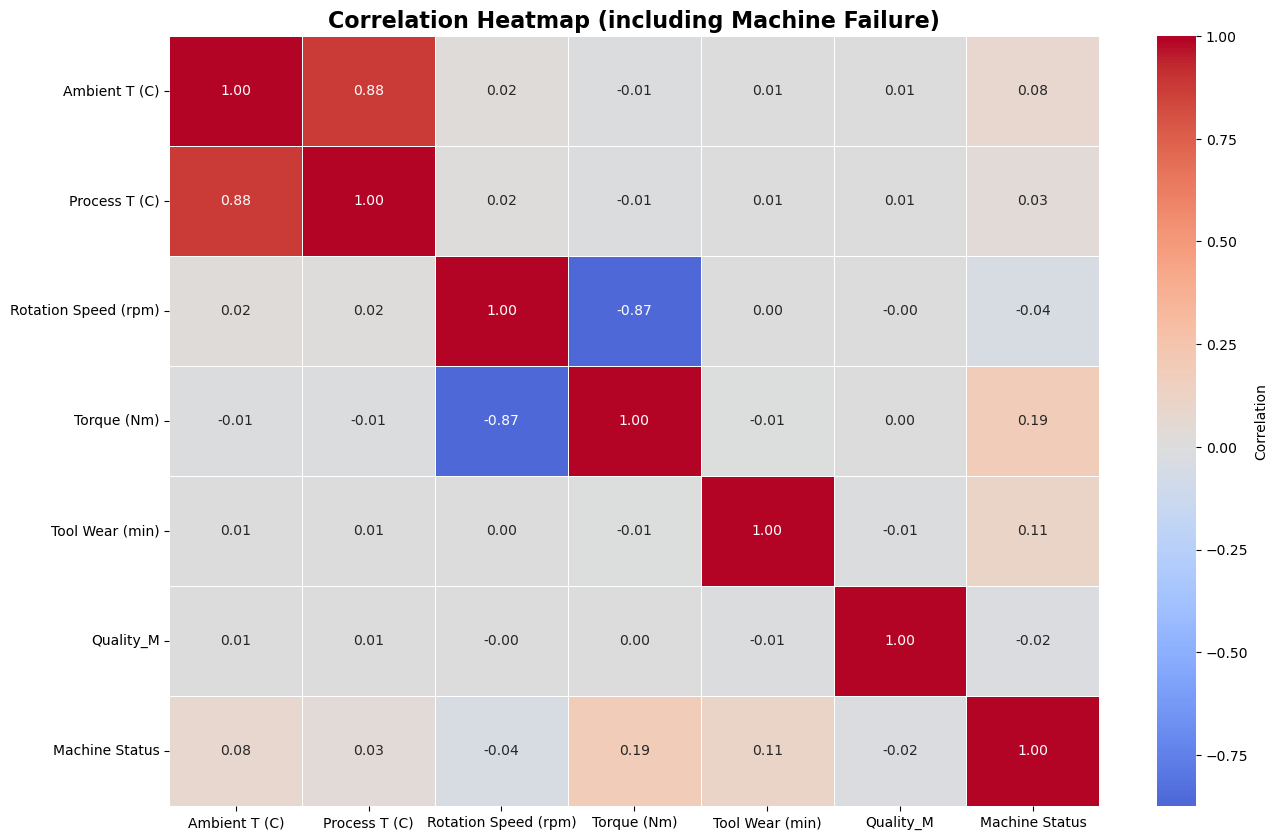

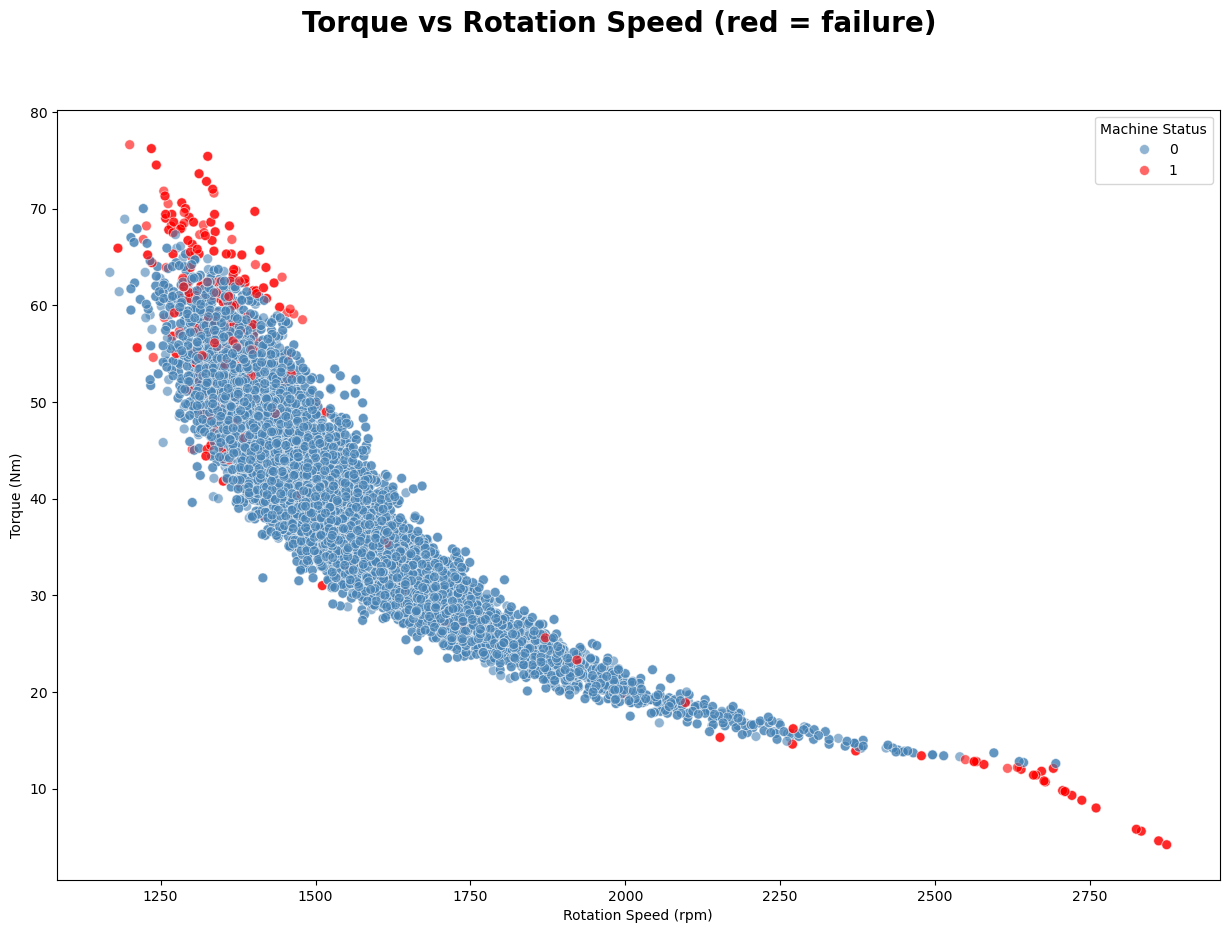

In [12]:
num_cols = [
    'Ambient T (C)',
    'Process T (C)',
    'Rotation Speed (rpm)',
    'Torque (Nm)',
    'Tool Wear (min)',
    'Quality_M'
]

# 1. Histograms of each feature, split by machine status
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df,
                 x=col,
                 hue='Machine Status',
                 kde=True,
                 palette='Set1',
                 alpha=0.6,
                 bins=50)
    plt.title(f'Histogram of {col}', fontweight='bold')
    plt.legend(title='Status', labels=['Failure', 'Success'])
plt.suptitle('Machine Success Distribution (Histogram) ', fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()


# 2. Box plots (normal vs failure)
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='Machine Status',
                y=col,
                data=df,
                palette='Set2')
    plt.title(f'{col} by Machine Status', fontweight='bold')
    plt.xticks([0, 1], ['Normal', 'Failure'])

plt.suptitle('Feature Distributions by Machine Status\n(Normal vs Failure)', fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()


# 3. Correlation heatmap, including the target
plt.figure(figsize=(15, 10))
corr_cols = num_cols + ['Machine Status']
corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix,
            annot=True,
            cmap='coolwarm',
            center=0,
            fmt='.2f',
            linewidths=0.5,
            cbar_kws={'label': 'Correlation'})
plt.title('Correlation Heatmap (including Machine Failure)', fontsize=16, fontweight='bold')
plt.show()

# 4. Torque vs rotation speed, the strongest negative correlation in the heatmap
plt.figure(figsize=(15,10))
sns.scatterplot(x='Rotation Speed (rpm)',
                y='Torque (Nm)',
                hue='Machine Status',
                data=df,
                alpha=0.6,
                s=50,
                palette={0:'steelblue', 1:'red'})
plt.suptitle("Torque vs Rotation Speed (red = failure)", fontsize=20, fontweight='bold')
plt.show()

## 2. Modelling

Steps:
1. Train-test split
2. Cross-validate baseline models
3. Feature engineering
4. Retrain with the engineered features
5. Hyperparameter tuning
6. Final evaluation on the held-out test set

### 2.1 Train-Test Split

In [13]:
# Separate the target, then split 80/20.
# stratify=y keeps the same share of failures in the train and test sets.
X = df.drop(['Machine Status'], axis=1)
y = df['Machine Status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Training set shape: (14023, 7) (14023,)
Testing set shape: (3506, 7) (3506,)


### 2.2 Baseline models: 5-fold cross-validation

In [14]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Class weights balance the rare failure class for the tree ensembles
models = {
    'Random Forest': RandomForestClassifier(
        class_weight='balanced', n_estimators=300, random_state=42, n_jobs=-1
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=500, learning_rate=0.05, random_state=42
    ),
    'Extra Trees': ExtraTreesClassifier(
        class_weight='balanced', n_estimators=300, random_state=42, n_jobs=-1
    ),
}

print("5-fold cross-validation F1 score per model:\n")
for key, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='f1')
    q25, q50, q75 = np.quantile(scores, [0.25, 0.5, 0.75])
    print(f"{key:25} → mean F1: {scores.mean():.4f}, std: {scores.std():.4f}, "
          f"25%: {q25:.4f}, 50%: {q50:.4f}, 75%: {q75:.4f}")

5-fold cross-validation F1 score per model:



Random Forest             → mean F1: 0.7959, std: 0.0385, 25%: 0.7639, 50%: 0.7901, 75%: 0.8235


HistGradientBoosting      → mean F1: 0.8245, std: 0.0180, 25%: 0.8111, 50%: 0.8187, 75%: 0.8324


Extra Trees               → mean F1: 0.8295, std: 0.0245, 25%: 0.8242, 50%: 0.8313, 75%: 0.8375


**Baseline results:** Extra Trees had the highest mean F1 (0.83), and HistGradientBoosting was the most consistent across folds (standard deviation 0.018). Random Forest was lowest at 0.80.

### 2.3 Feature engineering

In [15]:
# Three features based on how the machines physically work:
#   mechanical stress        = torque × rotation speed
#   power (W)                = torque × rotation speed × 2π/60  (0.10472 = 2π/60)
#   temperature differential = process temperature − ambient temperature
df_new = df.copy()
df_new['mechanical_stress'] = df_new['Torque (Nm)'] * df_new['Rotation Speed (rpm)']
df_new['Power (W)'] = df_new['Torque (Nm)'] * df_new['Rotation Speed (rpm)'] * 0.10472
df_new['Temperature Differential (°C)'] = df_new['Process T (C)'] - df_new['Ambient T (C)']

# Drop the product quality columns
df_new.drop(columns=['Quality_L', 'Quality_M'], inplace=True)

### 2.4 Retrain with the engineered features

In [16]:
X_new = df_new.drop(['Machine Status'], axis=1)
y_new = df_new['Machine Status']

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_new, test_size=0.2, random_state=42, stratify=y_new
)
print(X_new.columns.tolist())

print("\n5-fold cross-validation F1 score (engineered features):\n")
for key, model in models.items():
    scores = cross_val_score(model, X_train_new, y_train_new, cv=kf, scoring='f1')
    q25, q50, q75 = np.quantile(scores, [0.25, 0.5, 0.75])
    print(f"{key:25} → mean F1: {scores.mean():.4f}, std: {scores.std():.4f}, "
          f"25%: {q25:.4f}, 50%: {q50:.4f}, 75%: {q75:.4f}")

['Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)', 'Tool Wear (min)', 'mechanical_stress', 'Power (W)', 'Temperature Differential (°C)']

5-fold cross-validation F1 score (engineered features):



Random Forest             → mean F1: 0.8871, std: 0.0335, 25%: 0.8736, 50%: 0.8913, 75%: 0.9112


HistGradientBoosting      → mean F1: 0.8389, std: 0.0220, 25%: 0.8313, 50%: 0.8391, 75%: 0.8475


Extra Trees               → mean F1: 0.8758, std: 0.0258, 25%: 0.8655, 50%: 0.8786, 75%: 0.8913


### 2.5 Hyperparameter tuning

Random Forest gained the most from the engineered features (mean F1 0.80 → 0.89), so I tune it.

In [17]:
param_grid = {
    'n_estimators': [100, 300, 500],        # number of trees
    'max_depth': [None, 10, 20, 30],        # maximum depth of each tree
    'min_samples_split': [2, 5, 10],        # min samples to split a node
    'min_samples_leaf': [1, 2, 4],          # min samples in a leaf
    'max_features': ['sqrt', 'log2', None]  # features considered at each split
}

# Randomized search: tries 10 random combinations with 5-fold CV on the training set
random_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train_new, y_train_new)
print("Best hyperparameters:", random_search.best_params_)

Best hyperparameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}


### 2.6 Final evaluation on the held-out test set

In [18]:
best_rf = random_search.best_estimator_

y_pred = best_rf.predict(X_test_new)
f1 = f1_score(y_test_new, y_pred)
print(f"Test F1 score (tuned Random Forest): {f1:.4f}")

Test F1 score (tuned Random Forest): 0.9258


In [19]:
print(classification_report(y_test_new, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3387
           1       0.96      0.89      0.93       119

    accuracy                           1.00      3506
   macro avg       0.98      0.94      0.96      3506
weighted avg       1.00      1.00      1.00      3506

